# Trabajo Sumativo Unidad 3

## Algoritmos no supervisados: comparación con y sin PCA

**Asignatura:** Machine Learning  
**Carrera:** Ingeniería Civil Industrial  
**Integrantes Grupo 9:**

- Manuel Flores
- Miguel Aguirre
- Richard Salazar
- Miguel Venegas

**Profesor:** Franco Mansilla  
**Módulo:** eINGT1029-01

# Introducción

En las unidades anteriores se trabajó con el conjunto de datos **Store Sales - Time Series Forecasting** de Kaggle. Primero se realizó la revisión y preparación de los datos y posteriormente se construyó un problema de clasificación binaria mediante la variable `demanda_alta`.

En esta tercera etapa se utilizó la misma base para aplicar técnicas de aprendizaje no supervisado. El objetivo fue identificar agrupaciones naturales entre las observaciones sin utilizar la variable objetivo durante el entrenamiento de los algoritmos. Posteriormente, como la variable `demanda_alta` ya era conocida por el trabajo anterior, se utilizó solamente al final para revisar si los grupos encontrados presentaban diferencias respecto de esa clasificación.

El desarrollo considera la preparación de los datos, un experimento con y sin reducción de dimensionalidad mediante PCA, la comparación de cinco algoritmos de clustering basados en distancia y densidad, y la evaluación de los resultados mediante métricas internas.

# Punto 1. Preparación de datos

Para mantener continuidad en el análisis, se utiliza nuevamente la base `train`. La preparación conserva la definición de la variable `demanda_alta` y utiliza el mismo conjunto de variables de entrada, evitando incorporar directamente la venta del mismo día en la formación de los clusters.

En esta etapa se revisan datos faltantes y duplicados, se transforman las variables categóricas mediante One-Hot Encoding y se estandarizan las variables numéricas. La estandarización es especialmente importante en algoritmos que dependen de distancias, ya que variables con escalas diferentes pueden influir de manera desigual en el cálculo de proximidad entre observaciones.

## 1.1 Importación de librerías

Se importan las librerías necesarias para preparar la base, aplicar PCA, entrenar los algoritmos de clustering y calcular las métricas de evaluación.

In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

from google.colab import files

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors

from sklearn.cluster import (
    KMeans,
    AgglomerativeClustering,
    DBSCAN,
    OPTICS,
    HDBSCAN
)

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

SEMILLA = 2025

## 1.2 Carga de la base de datos

Se carga la base `train`, utilizada también en los trabajos anteriores. La columna `date` se transforma directamente a formato fecha para mantener el tratamiento temporal de la información.

In [48]:
uploaded = files.upload()

nombre_train = next(
    nombre for nombre in uploaded.keys()
    if nombre.lower().startswith("train")
)

train = pd.read_csv(
    nombre_train,
    parse_dates=["date"]
)

print("Dimensión de la base:", train.shape)
print("Período:", train["date"].min(), "a", train["date"].max())

train.head()

Saving train.csv to train (1).csv
Dimensión de la base: (3000888, 6)
Período: 2013-01-01 00:00:00 a 2017-08-15 00:00:00


,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


## 1.3 Limpieza y reconstrucción de la variable de referencia

No se identificaron duplicados en la base principal y los valores extremos de `sales` se conservaron, ya que no existía evidencia suficiente para considerarlos errores. Este criterio se mantuvo durante el desarrollo del presente análisis.

Posteriormente, se calculó el promedio de ventas de los 28 días anteriores para cada combinación de tienda y familia de productos. A partir de este promedio se construyó la variable `demanda_alta`, que toma el valor 1 cuando la venta del día supera dicho promedio y 0 en caso contrario.

La variable `demanda_alta` se conservó únicamente como referencia para la evaluación final de los clusters y no se incorporó como variable de entrada en los algoritmos de aprendizaje no supervisado.

In [49]:
# Ordenar por tienda, familia y fecha
datos = train.sort_values(
    ["store_nbr", "family", "date"]
).copy()

# Revisar duplicados según la clave principal
duplicados = datos.duplicated(
    subset=["date", "store_nbr", "family"]
).sum()

print("Duplicados encontrados:", duplicados)

if duplicados > 0:
    datos = datos.drop_duplicates(
        subset=["date", "store_nbr", "family"]
    ).copy()

# Promedio de los 28 días anteriores
grupo_ventas = datos.groupby(
    ["store_nbr", "family"]
)["sales"]

datos["promedio_28d"] = grupo_ventas.transform(
    lambda x: x.shift(1).rolling(28).mean()
)

# Variable utilizada previamente en la trabajo sumativo 2
datos["demanda_alta"] = (
    datos["sales"] > datos["promedio_28d"]
).astype(int)

# Eliminar solo registros que no tienen todavía 28 días de historia
datos = datos.dropna(
    subset=["promedio_28d"]
).copy()

# Variables derivadas de la fecha
datos["year"] = datos["date"].dt.year
datos["month"] = datos["date"].dt.month
datos["dayofweek"] = datos["date"].dt.dayofweek

print("Registros disponibles después de preparar la base:", len(datos))
print("Valores faltantes en promedio_28d:", datos["promedio_28d"].isna().sum())

Duplicados encontrados: 0
Registros disponibles después de preparar la base: 2950992
Valores faltantes en promedio_28d: 0


## 1.4 Selección de variables y muestra de trabajo

Se utilizaron como variables de entrada la tienda, la familia de productos, las promociones, el promedio histórico de 28 días y variables asociadas a la fecha.

La variable `sales` no se utilizó directamente en el clustering, porque participa en la construcción de `demanda_alta`. De esta forma, se evitó que la comparación posterior entre los clusters y la variable conocida estuviera condicionada directamente por haber utilizado la misma venta para formar los grupos.

Para controlar el tiempo de cálculo se trabajó con una muestra aleatoria de 6.000 observaciones correspondientes al período comprendido entre 2013 y 2015. La muestra se obtuvo sin utilizar `demanda_alta`, manteniendo así la formación de los grupos como un proceso no supervisado.

Aunque `store_nbr` aparece representada numéricamente, corresponde a un identificador de tienda y no a una magnitud cuantitativa. Por esta razón, se trató como una variable categórica.

In [50]:
variables_categoricas = [
    "store_nbr",
    "family"
]

variables_numericas = [
    "onpromotion",
    "promedio_28d",
    "year",
    "month",
    "dayofweek"
]

variables_modelo = variables_categoricas + variables_numericas

# Mantener el mismo período de entrenamiento usado anteriormente
datos_modelo = datos[
    datos["date"] <= "2015-12-31"
].copy()

# Revisión de faltantes en las variables que se usarán
print("Valores faltantes por variable:")
print(datos_modelo[variables_modelo].isna().sum())

# Muestra aleatoria para hacer viable el benchmarking de clustering
TAMANO_MUESTRA = min(6000, len(datos_modelo))

muestra = datos_modelo.sample(
    n=TAMANO_MUESTRA,
    random_state=SEMILLA
).copy()

X = muestra[variables_modelo].copy()
y_referencia = muestra["demanda_alta"].copy()

print("\nTamaño de la muestra:", X.shape)
print("Distribución de demanda_alta en la muestra:")
print((y_referencia.value_counts(normalize=True).sort_index() * 100).round(2))

Valores faltantes por variable:
store_nbr       0
family          0
onpromotion     0
promedio_28d    0
year            0
month           0
dayofweek       0
dtype: int64

Tamaño de la muestra: (6000, 7)
Distribución de demanda_alta en la muestra:
demanda_alta
0    70.18
1    29.82
Name: proportion, dtype: float64


## 1.5 One-Hot Encoding y Estandarización

Las variables `store_nbr` y `family` se tratan como categóricas y se transforman mediante One-Hot Encoding. Las variables numéricas se estandarizan con `StandardScaler` para evitar que una variable tenga más peso que otra solamente por su escala.

Este tratamiento se aplica antes del clustering porque los algoritmos de distancia y densidad dependen de la proximidad entre observaciones y, por lo tanto, son sensibles a diferencias de escala.

In [54]:
preprocesador = ColumnTransformer(
    transformers=[
        (
            "categoricas",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            variables_categoricas
        ),
        (
            "numericas",
            StandardScaler(),
            variables_numericas
        )
    ]
)

X_preparado = preprocesador.fit_transform(X)

print("Dimensión original de la muestra:", X.shape)
print("Dimensión después del preprocesamiento:", X_preparado.shape)

Dimensión original de la muestra: (6000, 7)
Dimensión después del preprocesamiento: (6000, 92)


# Punto 2. Experimento con y sin PCA

Se procede con la comparación de una base con PCA y otra sin PCA.
Para ello se mantuvieron dos representaciones de la misma muestra.

La primera conservó todas las variables generadas después del preprocesamiento. La segunda aplicó Análisis de Componentes Principales para reducir la dimensionalidad manteniendo la mayor parte de la variabilidad disponible.

La selección de componentes puede realizarse a partir de la varianza explicada acumulada. Para este trabajo se utilizó un umbral del 90%, valor que se encuentra dentro del rango habitual señalado en el material de estudio.

## 2.1 Base sin PCA

La primera versión corresponde directamente a la matriz preprocesada. Esta base conserva todas las columnas obtenidas luego de aplicar One-Hot Encoding y estandarización.

In [55]:
X_sin_pca = X_preparado.copy()

print("Base sin PCA:", X_sin_pca.shape)

Base sin PCA: (6000, 92)


## 2.2 Base con PCA y selección del número mínimo de componentes

Primero se ajustó PCA utilizando todas las componentes disponibles para observar la varianza explicada acumulada. Luego se seleccionó el número mínimo de componentes que permitió superar el 90% de varianza explicada.

Número mínimo de componentes: 50
Varianza acumulada: 90.03 %


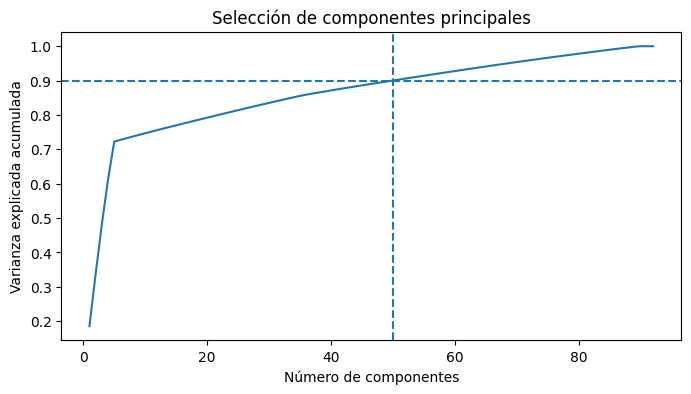

In [56]:
# PCA inicial para revisar la varianza explicada
pca_completo = PCA(
    random_state=SEMILLA
)

pca_completo.fit(X_preparado)

varianza_acumulada = np.cumsum(
    pca_completo.explained_variance_ratio_
)

# Número mínimo de componentes para explicar al menos 90% de la varianza
UMBRAL_VARIANZA = 0.90

n_componentes = int(
    np.argmax(varianza_acumulada >= UMBRAL_VARIANZA) + 1
)

print("Número mínimo de componentes:", n_componentes)
print(
    "Varianza acumulada:",
    round(varianza_acumulada[n_componentes - 1] * 100, 2),
    "%"
)

plt.figure(figsize=(8, 4))
plt.plot(
    range(1, len(varianza_acumulada) + 1),
    varianza_acumulada
)
plt.axhline(UMBRAL_VARIANZA, linestyle="--")
plt.axvline(n_componentes, linestyle="--")
plt.xlabel("Número de componentes")
plt.ylabel("Varianza explicada acumulada")
plt.title("Selección de componentes principales")
plt.show()

In [57]:
pca = PCA(
    n_components=n_componentes,
    random_state=SEMILLA
)

X_con_pca = pca.fit_transform(X_preparado)

print("Dimensión sin PCA:", X_sin_pca.shape)
print("Dimensión con PCA:", X_con_pca.shape)
print(
    "Varianza conservada:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

Dimensión sin PCA: (6000, 92)
Dimensión con PCA: (6000, 50)
Varianza conservada: 90.03 %


## 2.3 Comparación de las dos bases

La comparación permite revisar si la reducción de dimensionalidad mejora la separación de los grupos o simplifica el espacio de análisis sin perder una proporción importante de la información original. Ambas bases fueron sometidas al mismo challenge de algoritmos.

In [58]:
resumen_pca = pd.DataFrame({
    "Escenario": ["Sin PCA", "Con PCA"],
    "Observaciones": [X_sin_pca.shape[0], X_con_pca.shape[0]],
    "Variables / Componentes": [X_sin_pca.shape[1], X_con_pca.shape[1]]
})

resumen_pca

,Escenario,Observaciones,Variables / Componentes
0,Sin PCA,6000,92
1,Con PCA,6000,50


# Punto 3. Challenge entre algoritmos (benchmarking)

Se compararon cinco algoritmos de clustering, incluyendo métodos basados en distancia y métodos basados en densidad:

- **K-Means:** agrupa observaciones en torno a centroides.
- **Clustering jerárquico aglomerativo:** construye grupos a partir de la cercanía entre observaciones.
- **DBSCAN:** identifica regiones densas y permite clasificar puntos como ruido.
- **OPTICS:** extiende la lógica de densidad y puede representar estructuras con densidades diferentes.
- **HDBSCAN:** genera una estructura jerárquica basada en densidad y puede separar grupos sin fijar previamente su cantidad.

Los cinco modelos se ejecutaron tanto sobre la base sin PCA como sobre la base reducida con PCA.

## 3.1 Selección del número de clusters para los métodos de distancia

K-Means y el método aglomerativo requieren definir previamente una cantidad de grupos. Para evitar utilizar la variable `demanda_alta` en esta decisión, se probaron valores entre 2 y 6 clusters para cada algoritmo y escenario.

Para cada combinación se calculó el Silhouette Score y se seleccionó el número de clusters que presentó el mayor valor. De esta forma, tanto K-Means como el método aglomerativo fueron evaluados utilizando su propia cantidad de clusters más adecuada según la estructura interna de los datos.

In [59]:
def seleccionar_k(X_datos, nombre_escenario, tipo_modelo):

    resultados_k = []

    for k in range(2, 7):

        if tipo_modelo == "K-Means":

            modelo = KMeans(
                n_clusters=k,
                n_init=20,
                random_state=SEMILLA
            )

        elif tipo_modelo == "Aglomerativo":

            modelo = AgglomerativeClustering(
                n_clusters=k,
                linkage="ward"
            )

        etiquetas = modelo.fit_predict(
            X_datos
        )

        sil = silhouette_score(
            X_datos,
            etiquetas,
            sample_size=min(
                2000,
                len(X_datos)
            ),
            random_state=SEMILLA
        )

        resultados_k.append({
            "k": k,
            "Silhouette": sil
        })

    tabla = pd.DataFrame(
        resultados_k
    )

    mejor_k = int(
        tabla.loc[
            tabla["Silhouette"].idxmax(),
            "k"
        ]
    )

    print(
        nombre_escenario,
        "-",
        tipo_modelo,
        "- mejor k:",
        mejor_k
    )

    return tabla, mejor_k


# K-Means sin PCA
tabla_kmeans_sin, k_kmeans_sin = seleccionar_k(
    X_sin_pca,
    "Sin PCA",
    "K-Means"
)

# Aglomerativo sin PCA
tabla_aglo_sin, k_aglo_sin = seleccionar_k(
    X_sin_pca,
    "Sin PCA",
    "Aglomerativo"
)

# K-Means con PCA
tabla_kmeans_con, k_kmeans_con = seleccionar_k(
    X_con_pca,
    "Con PCA",
    "K-Means"
)

# Aglomerativo con PCA
tabla_aglo_con, k_aglo_con = seleccionar_k(
    X_con_pca,
    "Con PCA",
    "Aglomerativo"
)


print("\nK-Means - Sin PCA")
display(
    tabla_kmeans_sin.round(4)
)

print("\nAglomerativo - Sin PCA")
display(
    tabla_aglo_sin.round(4)
)

print("\nK-Means - Con PCA")
display(
    tabla_kmeans_con.round(4)
)

print("\nAglomerativo - Con PCA")
display(
    tabla_aglo_con.round(4)
)

Sin PCA - K-Means - mejor k: 2
Sin PCA - Aglomerativo - mejor k: 2
Con PCA - K-Means - mejor k: 4
Con PCA - Aglomerativo - mejor k: 2

K-Means - Sin PCA


,k,Silhouette
0,2,0.5472
1,3,0.1375
2,4,0.1403
3,5,0.1380
4,6,0.1354



Aglomerativo - Sin PCA


,k,Silhouette
0,2,0.3961
1,3,0.3486
2,4,0.1100
3,5,0.0861
4,6,0.0851



K-Means - Con PCA


,k,Silhouette
0,2,0.1508
1,3,0.1548
2,4,0.1660
3,5,0.1474
4,6,0.1634



Aglomerativo - Con PCA


,k,Silhouette
0,2,0.4488
1,3,0.3891
2,4,0.1165
3,5,0.1124
4,6,0.0962


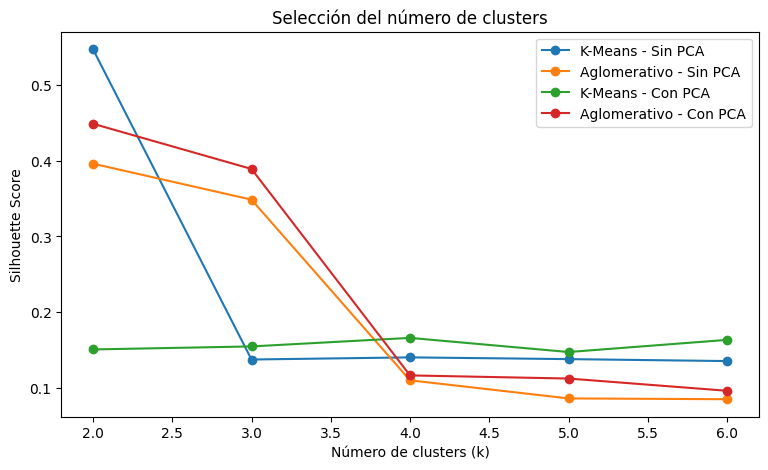

In [60]:
plt.figure(figsize=(9, 5))

plt.plot(
    tabla_kmeans_sin["k"],
    tabla_kmeans_sin["Silhouette"],
    marker="o",
    label="K-Means - Sin PCA"
)

plt.plot(
    tabla_aglo_sin["k"],
    tabla_aglo_sin["Silhouette"],
    marker="o",
    label="Aglomerativo - Sin PCA"
)

plt.plot(
    tabla_kmeans_con["k"],
    tabla_kmeans_con["Silhouette"],
    marker="o",
    label="K-Means - Con PCA"
)

plt.plot(
    tabla_aglo_con["k"],
    tabla_aglo_con["Silhouette"],
    marker="o",
    label="Aglomerativo - Con PCA"
)

plt.xlabel("Número de clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Selección del número de clusters")
plt.legend()
plt.show()

## 3.2 Estimación de ε para DBSCAN

DBSCAN requiere definir el radio `eps` y un número mínimo de puntos. Para ello, se utiliza la distancia al k-ésimo vecino como apoyo para identificar un valor razonable de `eps`.

Para mantener una ejecución reproducible, se calculó la distancia al décimo vecino y se utilizó una aproximación automática del codo, identificando el punto de mayor separación respecto de la diagonal en la curva normalizada. El mismo procedimiento se aplicó por separado a la base con PCA y a la base sin PCA.

In [61]:
def estimar_eps_codo(X_datos, min_samples=10):
    vecinos = NearestNeighbors(
        n_neighbors=min_samples
    )

    vecinos.fit(X_datos)
    distancias, _ = vecinos.kneighbors(X_datos)

    k_distancias = np.sort(
        distancias[:, -1]
    )

    x = np.linspace(0, 1, len(k_distancias))

    rango_y = np.ptp(k_distancias)

    if rango_y == 0:
        return max(float(k_distancias[-1]), 1e-6), k_distancias, len(k_distancias) - 1

    y = (
        (k_distancias - k_distancias.min())
        / rango_y
    )

    # Aproximación del codo: mayor separación respecto de la diagonal
    indice_codo = int(
        np.argmax(x - y)
    )

    eps = max(
        float(k_distancias[indice_codo]),
        1e-6
    )

    return eps, k_distancias, indice_codo


eps_sin_pca, kdist_sin, codo_sin = estimar_eps_codo(
    X_sin_pca
)

eps_con_pca, kdist_con, codo_con = estimar_eps_codo(
    X_con_pca
)

print("eps estimado sin PCA:", round(eps_sin_pca, 4))
print("eps estimado con PCA:", round(eps_con_pca, 4))

eps estimado sin PCA: 2.1175
eps estimado con PCA: 1.8921


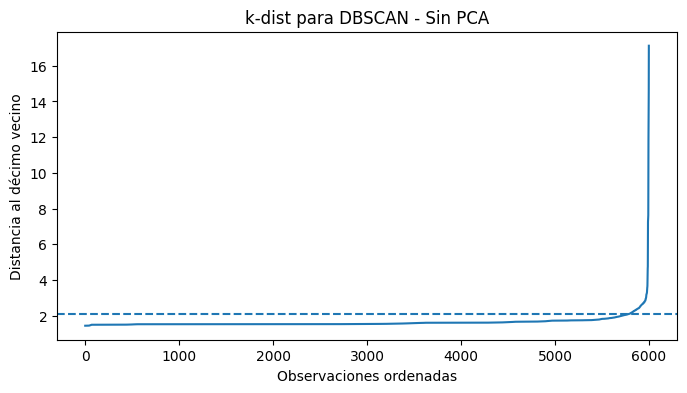

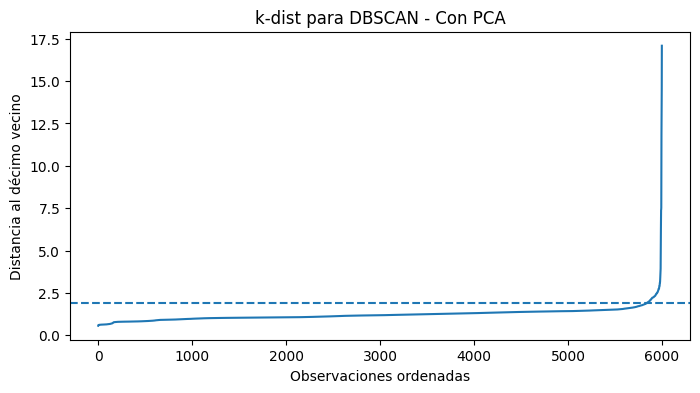

In [62]:
plt.figure(figsize=(8, 4))
plt.plot(kdist_sin)
plt.axhline(eps_sin_pca, linestyle="--")
plt.title("k-dist para DBSCAN - Sin PCA")
plt.xlabel("Observaciones ordenadas")
plt.ylabel("Distancia al décimo vecino")
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(kdist_con)
plt.axhline(eps_con_pca, linestyle="--")
plt.title("k-dist para DBSCAN - Con PCA")
plt.xlabel("Observaciones ordenadas")
plt.ylabel("Distancia al décimo vecino")
plt.show()

## 3.3 Ejecución de los cinco modelos

Se utilizaron configuraciones equivalentes para ambos escenarios. En los métodos basados en distancia, K-Means y el método aglomerativo utilizaron el número de clusters seleccionado individualmente mediante el Silhouette Score.

Los algoritmos basados en densidad determinaron la cantidad de grupos a partir de la distribución de las observaciones. En estos modelos también se registró el porcentaje de observaciones clasificadas como ruido, ya que una proporción elevada de puntos sin asignar puede reducir la utilidad de la segmentación para interpretar la base completa.

In [63]:
def crear_modelos(
    k_kmeans,
    k_aglomerativo,
    eps,
    n_observaciones
):

    min_cluster = max(
        30,
        int(n_observaciones * 0.01)
    )

    return {

        "K-Means": KMeans(
            n_clusters=k_kmeans,
            n_init=20,
            random_state=SEMILLA
        ),

        "Aglomerativo": AgglomerativeClustering(
            n_clusters=k_aglomerativo,
            linkage="ward"
        ),

        "DBSCAN": DBSCAN(
            eps=eps,
            min_samples=10
        ),

        "OPTICS": OPTICS(
            min_samples=10,
            xi=0.05,
            min_cluster_size=min_cluster
        ),

        "HDBSCAN": HDBSCAN(
            min_cluster_size=min_cluster,
            min_samples=10
        )
    }


experimentos = {

    "Sin PCA": {
        "X": X_sin_pca,
        "k_kmeans": k_kmeans_sin,
        "k_aglomerativo": k_aglo_sin,
        "eps": eps_sin_pca
    },

    "Con PCA": {
        "X": X_con_pca,
        "k_kmeans": k_kmeans_con,
        "k_aglomerativo": k_aglo_con,
        "eps": eps_con_pca
    }
}

## 3.4 Función de evaluación común

Para comparar los modelos se utilizaron tres métricas internas:

- **Silhouette Score:** valores más altos indican mejor cohesión y separación.
- **Davies-Bouldin:** valores más bajos representan clusters más compactos y separados.
- **Calinski-Harabasz:** valores más altos indican una mejor relación entre separación y dispersión interna.

En los algoritmos de densidad, las métricas internas se calcularon sobre los puntos asignados a clusters y se informó por separado el porcentaje de ruido. Esto evita tratar el ruido como si fuera un cluster convencional.

In [64]:
def evaluar_clustering(
    X_datos,
    etiquetas,
    nombre_modelo,
    escenario
):
    etiquetas = np.asarray(etiquetas)

    ruido_pct = (
        np.mean(etiquetas == -1) * 100
        if -1 in etiquetas
        else 0.0
    )

    mascara = etiquetas != -1
    etiquetas_validas = etiquetas[mascara]
    X_validos = X_datos[mascara]

    clusters = np.unique(etiquetas_validas)
    n_clusters = len(clusters)

    sil = np.nan
    db = np.nan
    ch = np.nan

    if (
        n_clusters >= 2
        and len(etiquetas_validas) > n_clusters
    ):
        sil = silhouette_score(
            X_validos,
            etiquetas_validas,
            sample_size=min(2000, len(etiquetas_validas)),
            random_state=SEMILLA
        )

        db = davies_bouldin_score(
            X_validos,
            etiquetas_validas
        )

        ch = calinski_harabasz_score(
            X_validos,
            etiquetas_validas
        )

    return {
        "Escenario": escenario,
        "Modelo": nombre_modelo,
        "Clusters": n_clusters,
        "Ruido_%": ruido_pct,
        "Silhouette": sil,
        "Davies-Bouldin": db,
        "Calinski-Harabasz": ch
    }

Para reducir el costo de cálculo, el Silhouette Score se estimó utilizando una muestra máxima de 2.000 observaciones, manteniendo una semilla fija para asegurar la reproducibilidad.

In [65]:
resultados = []
etiquetas_modelos = {}

for escenario, config in experimentos.items():
    print("Ejecutando:", escenario)

    X_actual = config["X"]

    modelos = crear_modelos(
        k_kmeans=config["k_kmeans"],
        k_aglomerativo=config["k_aglomerativo"],
        eps=config["eps"],
        n_observaciones=len(X_actual)
    )

    for nombre, modelo in modelos.items():
        print("  -", nombre)

        etiquetas = modelo.fit_predict(
            X_actual
        )

        etiquetas_modelos[(escenario, nombre)] = etiquetas

        resultados.append(
            evaluar_clustering(
                X_actual,
                etiquetas,
                nombre,
                escenario
            )
        )

resultados_modelos = pd.DataFrame(resultados)

resultados_modelos.round(4)

Ejecutando: Sin PCA
  - K-Means
  - Aglomerativo
  - DBSCAN
  - OPTICS
  - HDBSCAN
Ejecutando: Con PCA
  - K-Means
  - Aglomerativo
  - DBSCAN
  - OPTICS
  - HDBSCAN


,Escenario,Modelo,Clusters,Ruido_%,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,Sin PCA,K-Means,2,0.0000,0.5472,1.2924,814.7285
1,Sin PCA,Aglomerativo,2,0.0000,0.3961,1.6278,716.4616
2,Sin PCA,DBSCAN,2,2.3167,0.4324,0.8027,35.5462
3,Sin PCA,OPTICS,1,0.4833,NaN,NaN,NaN
4,Sin PCA,HDBSCAN,2,96.8167,0.1778,1.9500,48.6338
5,Con PCA,K-Means,4,0.0000,0.1660,1.4682,1085.7848
6,Con PCA,Aglomerativo,2,0.0000,0.4488,1.4845,833.1080
7,Con PCA,DBSCAN,1,1.7167,NaN,NaN,NaN
8,Con PCA,OPTICS,14,84.4167,0.1869,1.9849,69.5273
9,Con PCA,HDBSCAN,2,35.3833,-0.0037,2.5393,29.9755


# Punto 4. Evaluación y selección del modelo

La elección del modelo se realiza utilizando las métricas obtenidas en el benchmarking. Se toma Silhouette como criterio principal porque permite comparar la cohesión interna y la separación entre grupos bajo una misma escala. Davies-Bouldin y Calinski-Harabasz se utilizan como apoyo para comprobar que la selección no dependa de una única medida.

En los métodos de densidad también se considera el porcentaje de ruido. Si una configuración deja más de la mitad de las observaciones sin asignar, no se utiliza como candidata principal, aunque presente una métrica interna favorable sobre el subconjunto restante.

## 4.1 Comparación de métricas

In [66]:
resultados_ordenados = resultados_modelos.sort_values(
    by=["Silhouette", "Davies-Bouldin"],
    ascending=[False, True],
    na_position="last"
).reset_index(drop=True)

resultados_ordenados.round(4)

,Escenario,Modelo,Clusters,Ruido_%,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,Sin PCA,K-Means,2,0.0000,0.5472,1.2924,814.7285
1,Con PCA,Aglomerativo,2,0.0000,0.4488,1.4845,833.1080
2,Sin PCA,DBSCAN,2,2.3167,0.4324,0.8027,35.5462
3,Sin PCA,Aglomerativo,2,0.0000,0.3961,1.6278,716.4616
4,Con PCA,OPTICS,14,84.4167,0.1869,1.9849,69.5273
5,Sin PCA,HDBSCAN,2,96.8167,0.1778,1.9500,48.6338
6,Con PCA,K-Means,4,0.0000,0.1660,1.4682,1085.7848
7,Con PCA,HDBSCAN,2,35.3833,-0.0037,2.5393,29.9755
8,Sin PCA,OPTICS,1,0.4833,NaN,NaN,NaN
9,Con PCA,DBSCAN,1,1.7167,NaN,NaN,NaN


## 4.2 Selección del modelo

Para seleccionar el modelo final se utilizó como criterio principal el Silhouette Score, priorizando las configuraciones con mayor cohesión interna y separación entre clusters. Como criterio complementario se consideró el índice Davies-Bouldin, donde valores menores representan un mejor resultado.

Además, para los algoritmos basados en densidad se evitó seleccionar configuraciones que clasificaran más del 50% de las observaciones como ruido.

Bajo estos criterios, K-Means sin PCA fue seleccionado como el modelo con mejor desempeño general, obteniendo un Silhouette Score de 0.5472, un índice Davies-Bouldin de 1.2924 y un Calinski-Harabasz de 814.73, sin observaciones clasificadas como ruido.

In [68]:
# Candidatos con métricas válidas
candidatos = resultados_modelos.dropna(
    subset=["Silhouette"]
).copy()

# Evitar seleccionar una solución que deje a la mayoría como ruido
candidatos_utiles = candidatos[
    candidatos["Ruido_%"] <= 50
].copy()

if candidatos_utiles.empty:
    candidatos_utiles = candidatos.copy()

mejor_fila = candidatos_utiles.sort_values(
    by=["Silhouette", "Davies-Bouldin"],
    ascending=[False, True]
).iloc[0]

mejor_escenario = mejor_fila["Escenario"]
mejor_modelo = mejor_fila["Modelo"]

print("Modelo seleccionado:", mejor_modelo)
print("Escenario:", mejor_escenario)
print("Silhouette:", round(mejor_fila["Silhouette"], 4))
print("Davies-Bouldin:", round(mejor_fila["Davies-Bouldin"], 4))
print("Calinski-Harabasz:", round(mejor_fila["Calinski-Harabasz"], 2))
print("Ruido (%):", round(mejor_fila["Ruido_%"], 2))

Modelo seleccionado: K-Means
Escenario: Sin PCA
Silhouette: 0.5472
Davies-Bouldin: 1.2924
Calinski-Harabasz: 814.73
Ruido (%): 0.0


## 4.3 Análisis de los clusters respecto de la variable `demanda_alta`

Una vez seleccionado K-Means sin PCA como modelo final, se compararon los clusters obtenidos con la variable `demanda_alta`.

Esta variable no fue utilizada durante la formación de los clusters, por lo que se incorpora únicamente en esta etapa como referencia para analizar si los grupos encontrados presentan diferencias respecto del comportamiento de la demanda.

In [69]:
etiquetas_finales = etiquetas_modelos[
    (mejor_escenario, mejor_modelo)
]

comparacion = pd.DataFrame({
    "cluster": etiquetas_finales,
    "demanda_alta": y_referencia.to_numpy()
})

# Tabla de composición por cluster
tabla_y = pd.crosstab(
    comparacion["cluster"],
    comparacion["demanda_alta"],
    normalize="index"
) * 100

# Asegurar ambas columnas si alguna categoría no aparece en un cluster
for clase in [0, 1]:
    if clase not in tabla_y.columns:
        tabla_y[clase] = 0.0

tabla_y = tabla_y[[0, 1]]
tabla_y.columns = [
    "Demanda normal/baja (%)",
    "Demanda alta (%)"
]

tabla_y["Cantidad"] = comparacion["cluster"].value_counts().sort_index()

tabla_y.round(2)

,Demanda normal/baja (%),Demanda alta (%),Cantidad
cluster,,,
0,70.56,29.44,5826
1,57.47,42.53,174


In [70]:
# Diferencia en la proporción de demanda alta entre clusters
clusters_sin_ruido = tabla_y.drop(
    index=-1,
    errors="ignore"
)

if len(clusters_sin_ruido) >= 2:
    diferencia_demanda = (
        clusters_sin_ruido["Demanda alta (%)"].max()
        - clusters_sin_ruido["Demanda alta (%)"].min()
    )

    print(
        "Diferencia máxima en demanda alta entre clusters:",
        round(diferencia_demanda, 2),
        "puntos porcentuales"
    )
else:
    diferencia_demanda = np.nan
    print("No existen al menos dos clusters válidos para comparar.")

Diferencia máxima en demanda alta entre clusters: 13.09 puntos porcentuales


### Interpretación

El Cluster 0 concentró 5.826 observaciones, de las cuales un 29,44% correspondió a demanda alta. Por su parte, el Cluster 1 estuvo compuesto por 174 observaciones y presentó un 42,53% de casos de demanda alta.

Entre ambos grupos se obtuvo una diferencia de 13,09 puntos porcentuales en la proporción de demanda alta. Esto indica que los clusters encontrados presentan diferencias respecto del comportamiento de la variable objetivo conocida.

Sin embargo, la separación no es completa, ya que ambos clusters contienen observaciones de demanda alta y de demanda normal o baja. Además, existe una diferencia importante en el tamaño de los grupos, debido a que la mayor parte de los registros se concentra en el Cluster 0.

Por lo tanto, el resultado muestra una diferenciación parcial del comportamiento de la demanda y no una separación directa entre las dos categorías de `demanda_alta`.

## 4.4 Visualización del modelo seleccionado

Para facilitar la interpretación se proyectan las observaciones en dos componentes principales. Esta transformación se utiliza únicamente con fines de visualización y no modifica el modelo seleccionado, ya que K-Means fue entrenado utilizando la base sin PCA.

Se presentan dos representaciones: la primera muestra los clusters encontrados por K-Means y la segunda utiliza la variable `demanda_alta` como referencia para observar su distribución dentro del mismo espacio bidimensional.

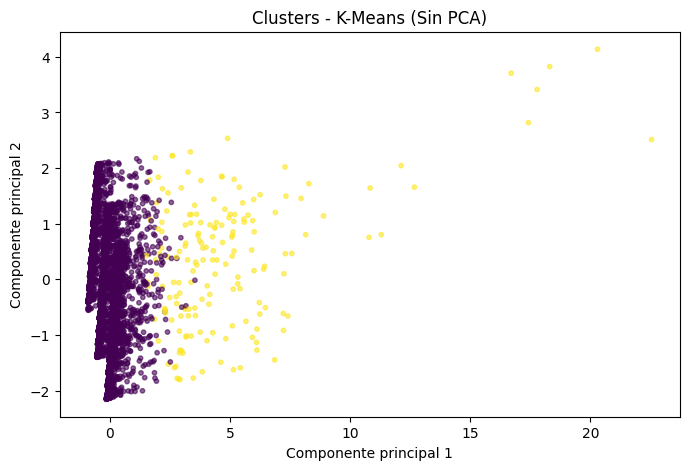

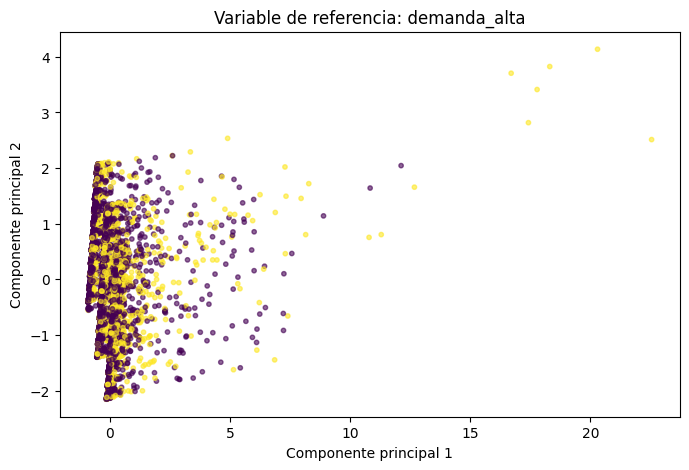

In [71]:
pca_visual = PCA(
    n_components=2,
    random_state=SEMILLA
)

X_visual = pca_visual.fit_transform(
    X_preparado
)

plt.figure(figsize=(8, 5))
plt.scatter(
    X_visual[:, 0],
    X_visual[:, 1],
    c=etiquetas_finales,
    s=10,
    alpha=0.6
)
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.title(
    f"Clusters - {mejor_modelo} ({mejor_escenario})"
)
plt.show()

plt.figure(figsize=(8, 5))
plt.scatter(
    X_visual[:, 0],
    X_visual[:, 1],
    c=y_referencia,
    s=10,
    alpha=0.6
)
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.title("Variable de referencia: demanda_alta")
plt.show()

### Interpretación de la visualización

En la representación de los clusters se observa que la mayor parte de las observaciones pertenece al Cluster 0, mientras que el Cluster 1 corresponde a un grupo considerablemente más pequeño y se extiende principalmente hacia valores mayores de la primera componente principal. Este comportamiento es consistente con la diferencia de tamaño observada previamente entre ambos grupos.

Al representar las mismas observaciones utilizando la variable `demanda_alta`, se observa una combinación de ambas categorías dentro del espacio proyectado, sin una separación claramente definida entre demanda alta y demanda normal o baja.

Este resultado coincide con el análisis cuantitativo anterior: el Cluster 1 presenta una mayor proporción de demanda alta que el Cluster 0, pero ambos grupos contienen observaciones de las dos categorías. Por lo tanto, los clusters presentan cierta diferenciación respecto del comportamiento de la demanda, aunque no corresponden directamente a una separación de la variable `demanda_alta`.

# Punto 5. Carga del cuaderno en GitHub

Como etapa final, el cuaderno desarrollado se incorporó al repositorio de GitHub mediante comandos Git. Para ello, se configuró el repositorio, se agregó el archivo, se registraron los cambios mediante un commit y posteriormente se realizó su carga a la rama principal.

In [ ]:
import os
import subprocess
import getpass

GITHUB_USER = "Mglaguirre"
REPO_DIR = "/content/Machine-Learning-Grupo-9"

# Solicitar token sin mostrarlo en pantalla
token = getpass.getpass(
    "Ingresa tu nuevo Personal Access Token de GitHub: "
)

# Crear un archivo temporal para entregar las credenciales a Git
askpass_path = "/tmp/git_askpass.py"

with open(askpass_path, "w") as f:
    f.write(
        """#!/usr/bin/env python3
import os
import sys

pregunta = sys.argv[1]

if "Username" in pregunta:
    print(os.environ["GITHUB_USER"])
elif "Password" in pregunta:
    print(os.environ["GITHUB_TOKEN"])
"""
    )

os.chmod(askpass_path, 0o700)

# Variables temporales de autenticación
env = os.environ.copy()
env["GIT_ASKPASS"] = askpass_path
env["GIT_TERMINAL_PROMPT"] = "0"
env["GITHUB_USER"] = GITHUB_USER
env["GITHUB_TOKEN"] = token

# Asegurar que la rama sea main
subprocess.run(
    [
        "git",
        "-C",
        REPO_DIR,
        "branch",
        "-M",
        "main"
    ],
    check=True
)

# Ejecutar push
resultado = subprocess.run(
    [
        "git",
        "-C",
        REPO_DIR,
        "push",
        "-u",
        "origin",
        "main"
    ],
    env=env,
    capture_output=True,
    text=True
)

# Eliminar credenciales de memoria
del token
env.pop("GITHUB_TOKEN", None)

if os.path.exists(askpass_path):
    os.remove(askpass_path)

# Mostrar resultado
if resultado.returncode == 0:
    print("Archivo cargado correctamente en GitHub.")
    print(resultado.stdout)
else:
    print("No se pudo realizar el push.")
    print(resultado.stderr)

# Conclusión

El desarrollo de este trabajo permitió aplicar técnicas de aprendizaje no supervisado sobre la misma base de datos utilizada durante las unidades anteriores, manteniendo continuidad con el análisis realizado sobre Store Sales - Time Series Forecasting.

Durante la preparación de los datos se conservaron las principales variables utilizadas previamente y se aplicaron las transformaciones necesarias para su utilización en algoritmos basados en distancia y densidad. Las variables categóricas fueron transformadas mediante One-Hot Encoding y las variables numéricas fueron estandarizadas, evitando que las diferencias de escala influyeran de manera excesiva en el cálculo de las distancias.

Posteriormente, se compararon dos escenarios: uno utilizando las variables preprocesadas sin reducción de dimensionalidad y otro aplicando PCA. Sobre ambos escenarios se evaluaron cinco algoritmos de clustering: K-Means, clustering aglomerativo, DBSCAN, OPTICS y HDBSCAN.

A partir de las métricas obtenidas, K-Means sin PCA presentó el mejor desempeño general, alcanzando un Silhouette Score de 0.5472, un índice Davies-Bouldin de 1.2924 y un Calinski-Harabasz de 814.73, sin observaciones clasificadas como ruido. La comparación con el escenario que incorporó PCA mostró además que la reducción de dimensionalidad no produjo una mejora para K-Means, ya que su Silhouette Score disminuyó a 0.1660.

Finalmente, los clusters obtenidos mediante K-Means fueron comparados con la variable `demanda_alta`, sin haber utilizado esta información durante la formación de los grupos. El Cluster 0 presentó un 29,44% de observaciones correspondientes a demanda alta, mientras que en el Cluster 1 esta proporción aumentó a 42,53%, generando una diferencia de 13,09 puntos porcentuales.

Estos resultados muestran que los grupos encontrados presentan diferencias respecto del comportamiento de la demanda, aunque no existe una separación completa entre ambas categorías. Además, la mayor parte de las observaciones quedó concentrada en uno de los clusters, por lo que el resultado debe interpretarse como una segmentación de perfiles con distinta propensión a presentar demanda alta y no como una clasificación directa de esta variable.

En síntesis, para los datos analizados K-Means sin PCA fue la alternativa que entregó la estructura de agrupamiento más clara entre los modelos evaluados, permitiendo identificar diferencias en el comportamiento de las observaciones sin utilizar previamente la variable objetivo.

# Bibliografía

- Universidad Mayor. (2026). *Unidad 3: Algoritmos no-supervisados*. Material de la asignatura Machine Learning.
- Kaggle. *Store Sales - Time Series Forecasting*. Dataset utilizado en las Unidades 1, 2 y 3.